
# EEG AD vs CN classification — Full pipeline (CNN+LSTM) with TQWT + classical features
**Generated:** 2025-11-30T06:19:24.867012Z

This notebook implements the full pipeline you requested:
- Reads local BIDS dataset at `C:\Users\sanja\Desktop\EEG_Project\EEG\eeg`
- Uses subjects `sub-001` → `sub-065` (AD and Cognitively Normal)
- Windowing: 5s windows with 50% overlap (sampling rate = 500 Hz)
- Feature extraction per window: time-domain, frequency-domain, nonlinear (Hjorth, TKEO), and **TQWT** subband statistics (Q=1.0, r=10, J=6)
- Model: PyTorch CNN+BiLSTM hybrid, trained on GPU (cuda:0) where available
- Class imbalance handling: Mixup, class-weighted cross-entropy
- Training: 10-fold subject-wise stratified CV, early stopping, LR scheduler, checkpoint saving (.pt)
- Visualizations: EDA and model evaluation plots


In [41]:

# Cell 2: Imports, device, seeds
import os, random, time, math, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.signal as signal
import mne
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report, accuracy_score
from sklearn.manifold import TSNE

warnings.filterwarnings('ignore')
DEVICE = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


Device: cuda:0


In [42]:

# Cell 3: Paths and global parameters
datasetPath = r"C:\Users\sanja\Desktop\EEG_Project\EEG\eeg"
labels_csv = os.path.join(datasetPath, 'derivatives', 'labels.csv')

SUBJECTS = [f"sub-{i:03d}" for i in range(1,66)]  # sub-001 .. sub-065 (AD + CN)
SR = 500  # sampling rate (Hz)
WIN_SEC = 5
WIN_SAMPLES = WIN_SEC * SR
OVERLAP = 0.5
STEP_SAMPLES = int(WIN_SAMPLES * (1 - OVERLAP))
TQWT_PARAMS = {'Q':1.0, 'r':10, 'J':6}
CHANNELS = ['Fp1','Fp2','F7','F3','Fz','F4','F8','T3','C3','Cz','C4','T4','T5','P3','Pz','P4','T6','O1','O2']

print('Window samples:', WIN_SAMPLES, 'Step samples:', STEP_SAMPLES)
print('Subjects to process:', len(SUBJECTS))


Window samples: 2500 Step samples: 1250
Subjects to process: 65


In [43]:

# Cell 4: Helper functions — preprocessing and feature extractors
from scipy import fftpack

def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = signal.butter(order, [low, high], btype='band')
    y = signal.filtfilt(b, a, data, axis=-1)
    return y

def epoch_signal(sig, win_samples, step_samples):
    n = sig.shape[-1]
    epochs = []
    for start in range(0, n - win_samples + 1, step_samples):
        epochs.append(sig[..., start:start+win_samples])
    if len(epochs) == 0:
        return np.zeros((0, sig.shape[0], win_samples))
    return np.stack(epochs, axis=0)  # (n_epochs, n_channels, win_samples)

def bandpower_from_psd(psd, freqs, fmin, fmax):
    mask = (freqs >= fmin) & (freqs <= fmax)
    if np.sum(mask)==0:
        return 0.0
    return np.trapz(psd[mask], freqs[mask])

def spectral_entropy(psd, freqs):
    psd_norm = psd / (np.sum(psd) + 1e-12)
    psd_norm = np.where(psd_norm<=0, 1e-12, psd_norm)
    return -np.sum(psd_norm * np.log2(psd_norm))

def dominant_frequency(psd, freqs):
    idx = np.argmax(psd)
    return float(freqs[idx])

def hjorth_parameters(x):
    dx = np.diff(x)
    ddx = np.diff(dx)
    var_x = np.var(x)
    var_dx = np.var(dx) if dx.size>0 else 0.0
    var_ddx = np.var(ddx) if ddx.size>0 else 0.0
    activity = var_x
    mobility = np.sqrt(var_dx / (var_x + 1e-12))
    complexity = np.sqrt((var_ddx / (var_dx + 1e-12)) / (var_dx / (var_x + 1e-12)) + 1e-12)
    return float(activity), float(mobility), float(complexity)

def tkeo(x):
    x = np.asarray(x)
    if x.size < 3:
        return np.array([0.0])
    return x[1:-1]**2 - x[:-2]*x[2:]

def compute_psd(x, fs):
    # Use Welch with 2s window for stable PSD on 5s epoch
    nperseg = min(len(x), fs*2)
    freqs, psd = signal.welch(x, fs=fs, nperseg=nperseg)
    return freqs, psd


In [44]:

# Cell 5: TQWT wrapper (attempt to import 'tqwt' package)
TQWT_AVAILABLE = False
try:
    import tqwt as _tqwt_pkg
    TQWT_AVAILABLE = True
    def tqwt_decompose(x, Q=1.0, r=10, J=6):
        # package tqwt provides tqwt.tqwt function returning list-like bands
        bands = _tqwt_pkg.tqwt(x, Q=Q, r=r, J=J)
        # ensure numpy arrays
        return [np.asarray(b) for b in bands]
except Exception as e:
    TQWT_AVAILABLE = False
    def tqwt_decompose(x, Q=1.0, r=10, J=6):
        # If package not available, raise explicit error to inform user to pip install tqwt
        raise RuntimeError('tqwt package not available. Please run: pip install tqwt')


print('TQWT available:', TQWT_AVAILABLE)


TQWT available: False


In [45]:

# Cell 6: Feature extraction for a single epoch (channels x samples)
def extract_features_epoch(epoch, fs=SR, tqwt_params=TQWT_PARAMS, use_tqwt=True):
    # epoch: (n_channels, n_samples)
    feats = []
    for ch in range(epoch.shape[0]):
        x = epoch[ch].astype(np.float32)
        # time domain
        mean = float(np.mean(x))
        rms = float(np.sqrt(np.mean(x**2)))
        activity, mobility, complexity = hjorth_parameters(x)
        tkeo_vals = tkeo(x)
        tkeo_mean = float(np.mean(tkeo_vals)) if tkeo_vals.size>0 else 0.0
        # PSD
        freqs, psd = compute_psd(x, fs)
        delta = float(bandpower_from_psd(psd, freqs, 0.5, 4))
        theta = float(bandpower_from_psd(psd, freqs, 4, 7))
        alpha = float(bandpower_from_psd(psd, freqs, 8, 12))
        beta = float(bandpower_from_psd(psd, freqs, 13, 30))
        spec_ent = float(spectral_entropy(psd, freqs))
        dom_freq = float(dominant_frequency(psd, freqs))
        # TQWT subbands stats
        tqwt_stats = []
        if use_tqwt:
            try:
                subbands = tqwt_decompose(x, **tqwt_params)
                for sb in subbands:
                    sb = np.asarray(sb)
                    tqwt_stats += [float(np.mean(sb)), float(np.std(sb)), float(np.sum(np.square(sb)))]
            except Exception as e:
                # If TQWT fails, warn once and put zeros
                print('Warning: TQWT failed for channel; setting TQWT features to zero. Error:', e)
                tqwt_stats = [0.0]*((tqwt_params['J']+1)*3)
        else:
            tqwt_stats = [0.0]*((tqwt_params['J']+1)*3)
        ch_feats = [mean, rms, activity, mobility, complexity, tkeo_mean,
                    delta, theta, alpha, beta, spec_ent, dom_freq] + tqwt_stats
        feats.extend(ch_feats)
    return np.array(feats, dtype=np.float32)


In [46]:

# Cell 7: Read labels.csv mapping
labels_df = pd.read_csv(labels_csv)
labels_df = labels_df.set_index('subject')
labels_df = labels_df.loc[[s for s in SUBJECTS if s in labels_df.index]]  # filter available
print('Labels loaded:', labels_df.shape)
labels_df.head()


Labels loaded: (65, 1)


,label
subject,
sub-001,AD
sub-002,AD
sub-003,AD
sub-004,AD
sub-005,AD


In [47]:

# Cell 8: Process a single subject: find raw file, read, preprocess, epoch, extract features
def find_raw_file(subject_id, root_path):
    subj_path = os.path.join(root_path, subject_id)
    if not os.path.exists(subj_path):
        return None
    ext_candidates = ['.edf', '.vhdr', '.fif', '.set', '.bdf']
    for root, dirs, files in os.walk(subj_path):
        for f in files:
            if any(f.lower().endswith(e) for e in ext_candidates):
                return os.path.join(root, f)
    return None

cache_dir = os.path.join('/mnt/data','eeg_feature_cache')
os.makedirs(cache_dir, exist_ok=True)

def process_subject(subject_id, use_tqwt=TQWT_AVAILABLE):
    out_file = os.path.join(cache_dir, f'{subject_id}_feats.npz')
    if os.path.exists(out_file):
        data = np.load(out_file, allow_pickle=True)
        return data['feats'], int(data['label'])
    raw_file = find_raw_file(subject_id, datasetPath)
    if raw_file is None:
        print(f'Raw not found for {subject_id} under {datasetPath}')
        return None
    try:
        raw = mne.io.read_raw(raw_file, preload=True, verbose=False)
    except Exception as e:
        print('Error reading', raw_file, e)
        return None
    picks = [ch for ch in CHANNELS if ch in raw.ch_names]
    if len(picks) < len(CHANNELS):
        print(f'Warning: missing channels for {subject_id}. Found {len(picks)} / {len(CHANNELS)}')
    sig = raw.copy().pick_channels(picks).get_data()  # (n_chan, n_samples)
    # bandpass 0.5-45
    sig = butter_bandpass_filter(sig, 0.5, 45.0, SR)
    # epoch into overlapping windows
    epochs = epoch_signal(sig, WIN_SAMPLES, STEP_SAMPLES)  # (n_epochs, n_chan, win_samples)
    if epochs.shape[0] == 0:
        print(f'No epochs for {subject_id} (recording too short)')
        return None
    feats_list = []
    for ep in epochs:
        try:
            feats_list.append(extract_features_epoch(ep, fs=SR, tqwt_params=TQWT_PARAMS, use_tqwt=use_tqwt))
        except Exception as e:
            # skip problematic epoch
            continue
    if len(feats_list) == 0:
        print(f'No valid feature epochs for {subject_id} after extraction')
        return None
    feats = np.stack(feats_list, axis=0)
    lbl = labels_df.loc[subject_id]['label']
    y = 1 if str(lbl).strip().upper().startswith('A') else 0
    np.savez_compressed(out_file, feats=feats, label=y)
    return feats, int(y)

# Quick test: do not run full processing yet
print('Ready to process subjects. Cache dir:', cache_dir)


Ready to process subjects. Cache dir: /mnt/data\eeg_feature_cache


In [48]:

# Cell 9: Process all subjects and build lists
FEATURES = []
LABELS = []
SUBJ_IDX = []

for subj in tqdm(SUBJECTS, desc='Subjects'):
    res = process_subject(subj, use_tqwt=TQWT_AVAILABLE)
    if res is None:
        continue
    feats, y = res
    FEATURES.append(feats)
    LABELS.append(y)
    SUBJ_IDX.append(subj)

print('Processed subjects:', len(SUBJ_IDX))


Subjects: 100%|██████████| 65/65 [00:00<00:00, 343.69it/s]

Processed subjects: 65


In [49]:

# Cell 10: Flatten windows and create arrays
X_all = []
y_all = []
subject_index = []

for subj, feats, lbl in zip(SUBJ_IDX, FEATURES, LABELS):
    for w in feats:
        X_all.append(w)
        y_all.append(lbl)
        subject_index.append(subj)

X_all = np.array(X_all, dtype=np.float32)
y_all = np.array(y_all, dtype=np.int64)
subject_index = np.array(subject_index)

print("Total windows:", X_all.shape[0])
print("Feature dimension (per window):", X_all.shape[1])
print("AD windows:", np.sum(y_all==1))
print("CN windows:", np.sum(y_all==0))


Total windows: 21434
Feature dimension (per window): 627
AD windows: 11707
CN windows: 9727


In [50]:

# Cell 11: PyTorch Dataset with mixup option
class EEGDataset(Dataset):
    def __init__(self, X, y, transform=None, mixup_alpha=None):
        self.X = X
        self.y = y
        self.transform = transform
        self.mixup_alpha = mixup_alpha

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]
        y = float(self.y[idx])   # force float label

        if self.mixup_alpha is not None:
            lam = np.random.beta(self.mixup_alpha, self.mixup_alpha)
            idx2 = np.random.randint(0, len(self.X))

            x2 = self.X[idx2]
            y2 = float(self.y[idx2])

            x = lam * x + (1 - lam) * x2
            y = lam * y + (1 - lam) * y2

        return torch.tensor(x, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)


In [51]:

# Cell 12: CNN + BiLSTM hybrid model (expects input: batch x features)
class CNN_LSTM(nn.Module):
    def __init__(self, input_dim, conv_channels=64, lstm_hidden=128, lstm_layers=2, dropout=0.3):
        super().__init__()
        self.input_dim = input_dim
        # treat feature vector as 1D sequence length = input_dim, channels=1
        self.conv = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Conv1d(32, conv_channels, kernel_size=5, padding=2),
            nn.BatchNorm1d(conv_channels),
            nn.ReLU()
        )
        self.lstm = nn.LSTM(input_size=conv_channels, hidden_size=lstm_hidden,
                            num_layers=lstm_layers, batch_first=True, bidirectional=True, dropout=dropout)
        self.fc = nn.Sequential(
            nn.Linear(lstm_hidden*2, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        # x: (B, F)
        x = x.unsqueeze(1)  # (B, 1, F)
        x = self.conv(x)    # (B, C, F)
        x = x.permute(0, 2, 1)  # (B, F, C)
        out, _ = self.lstm(x)   # (B, F, 2*H)
        out = out[:, -1, :]     # last timestep
        logits = self.fc(out).squeeze(-1)
        return logits


In [52]:

# Cell 13: Training utilities: criterion with class weights, metrics, early stopping helper
import math
def get_class_weights(y):
    # simple inverse frequency weights
    unique, counts = np.unique(y, return_counts=True)
    freq = dict(zip(unique, counts))
    total = len(y)
    weights = {}
    for k in unique:
        weights[k] = total / (len(unique) * freq[k])
    return weights

class EarlyStopping:
    def __init__(self, patience=10, verbose=False, delta=0.0, path='checkpoint.pt'):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.delta = delta
        self.path = path

    def __call__(self, score, model):
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(model)
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.save_checkpoint(model)
            self.counter = 0

    def save_checkpoint(self, model):
        torch.save(model.state_dict(), self.path)


In [53]:

# Cell 14: Training and evaluation functions (with tqdm progress bars)
from sklearn.metrics import roc_auc_score

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    preds = []
    trues = []
    pbar = tqdm(dataloader, desc='Train', leave=False)
    for xb, yb in pbar:
        xb = xb.to(device)
        yb = yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        if logits.dim()==0:
            logits = logits.unsqueeze(0)
        # if soft labels (mixup) use BCEWithLogitsLoss; detect yb dtype
        if yb.dtype==torch.float32:
            loss = nn.BCEWithLogitsLoss()(logits, yb.float())
            probs = torch.sigmoid(logits).detach().cpu().numpy()
            trues.extend(yb.detach().cpu().numpy().tolist())
            preds.extend(probs.tolist())
        else:
            loss = criterion(logits, yb)
            probs = torch.sigmoid(logits).detach().cpu().numpy()
            trues.extend(yb.detach().cpu().numpy().tolist())
            preds.extend(probs.tolist())
        loss.backward()
        optimizer.step()
        running_loss += float(loss.item()) * xb.size(0)
        pbar.set_postfix({'loss': f'{running_loss/((pbar.n+1)*xb.size(0)):.4f}'})
    avg_loss = running_loss / len(dataloader.dataset)
    try:
        auc = roc_auc_score(trues, preds)
    except Exception:
        auc = 0.0
    return avg_loss, auc

def eval_model(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    preds = []
    trues = []
    with torch.no_grad():
        pbar = tqdm(dataloader, desc='Eval', leave=False)
        for xb, yb in pbar:
            xb = xb.to(device)
            yb = yb.to(device)
            logits = model(xb)
            if yb.dtype==torch.float32:
                loss = nn.BCEWithLogitsLoss()(logits, yb.float())
                probs = torch.sigmoid(logits).detach().cpu().numpy()
                trues.extend(yb.detach().cpu().numpy().tolist())
                preds.extend(probs.tolist())
            else:
                loss = criterion(logits, yb)
                probs = torch.sigmoid(logits).detach().cpu().numpy()
                trues.extend(yb.detach().cpu().numpy().tolist())
                preds.extend(probs.tolist())
            running_loss += float(loss.item()) * xb.size(0)
    avg_loss = running_loss / len(dataloader.dataset)
    try:
        auc = roc_auc_score(trues, preds)
    except Exception:
        auc = 0.0
    return avg_loss, auc, np.array(trues), np.array(preds)


In [54]:

# Cell 15: 10-fold subject-wise stratified CV training
n_splits = 10
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

# Prepare subject-level labels for stratification: one label per subject
subj_labels = np.array([LABELS[i] for i in range(len(SUBJ_IDX))])
subj_array = np.array(SUBJ_IDX)

results = []
fold = 0
for train_idx, val_idx in skf.split(subj_array, subj_labels):
    fold += 1
    print(f'--- Fold {fold} / {n_splits} ---')
    train_subs = subj_array[train_idx]
    val_subs = subj_array[val_idx]
    # select windows belonging to those subjects
    train_mask = np.isin(subject_index, train_subs)
    val_mask = np.isin(subject_index, val_subs)
    X_train, y_train = X_all[train_mask], y_all[train_mask]
    X_val, y_val = X_all[val_mask], y_all[val_mask]
    print('Train windows:', X_train.shape[0], 'Val windows:', X_val.shape[0])
    # datasets and loaders
    mixup_alpha = 0.2
    train_dataset = EEGDataset(X_train, y_train, mixup_alpha=mixup_alpha)
    val_dataset = EEGDataset(X_val, y_val, mixup_alpha=None)
    batch_size = 64
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
    # model
    input_dim = X_train.shape[1]
    model = CNN_LSTM(input_dim=input_dim).to(DEVICE)
    # class weights
    class_weights = get_class_weights(y_train)
    weight_tensor = torch.tensor([class_weights.get(0,1.0), class_weights.get(1,1.0)], dtype=torch.float32).to(DEVICE)
    # we will use BCEWithLogits with pos_weight for binary imbalance when labels are hard ints
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(class_weights.get(1,1.0)).to(DEVICE))
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, verbose=True)
    # early stopping
    ckpt_path = f'/mnt/data/best_model_fold{fold}.pt'
    early_stopper = EarlyStopping(patience=12, verbose=True, path=ckpt_path)
    best_val_auc = 0.0
    num_epochs = 80
    history = {'train_loss':[], 'val_loss':[], 'train_auc':[], 'val_auc':[]}
    for epoch in range(1, num_epochs+1):
        print(f'Epoch {epoch}/{num_epochs}')
        train_loss, train_auc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
        val_loss, val_auc, val_trues, val_preds = eval_model(model, val_loader, criterion, DEVICE)
        scheduler.step(val_auc)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_auc'].append(train_auc)
        history['val_auc'].append(val_auc)
        print(f'  train_loss: {train_loss:.4f}, train_auc: {train_auc:.4f} | val_loss: {val_loss:.4f}, val_auc: {val_auc:.4f}')
        # early stopping uses validation AUC as score
        early_stopper(val_auc, model)
        if early_stopper.early_stop:
            print('Early stopping triggered.')
            break
    # load best model for this fold
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    # final eval on val set
    val_loss, val_auc, val_trues, val_preds = eval_model(model, val_loader, criterion, DEVICE)
    val_pred_labels = (val_preds >= 0.5).astype(int)
    acc = accuracy_score(val_trues, val_pred_labels)
    print(f'Fold {fold} final — Val AUC: {val_auc:.4f}, Acc: {acc:.4f}')
    results.append({'fold':fold, 'val_auc':float(val_auc), 'val_acc':float(acc), 'history':history, 'val_trues':val_trues, 'val_preds':val_preds, 'ckpt':ckpt_path})


--- Fold 1 / 10 ---
Train windows: 19167 Val windows: 2267
Epoch 1/80


  train_loss: 0.6906, train_auc: 0.0000 | val_loss: 0.6829, val_auc: 0.5532
Epoch 2/80


  train_loss: 0.6892, train_auc: 0.0000 | val_loss: 0.6834, val_auc: 0.4697
EarlyStopping counter: 1 out of 12
Epoch 3/80


  train_loss: 0.6902, train_auc: 0.0000 | val_loss: 0.6854, val_auc: 0.5000
EarlyStopping counter: 2 out of 12
Epoch 4/80


  train_loss: 0.6905, train_auc: 0.0000 | val_loss: 0.6844, val_auc: 0.4950
EarlyStopping counter: 3 out of 12
Epoch 5/80


...

  train_loss: 0.6879, train_auc: 0.0000 | val_loss: 0.6969, val_auc: 0.5021
EarlyStopping counter: 9 out of 12
Epoch 11/80


  train_loss: 0.6887, train_auc: 0.0000 | val_loss: 0.6966, val_auc: 0.5000
EarlyStopping counter: 10 out of 12
Epoch 12/80


  train_loss: 0.6884, train_auc: 0.0000 | val_loss: 0.6975, val_auc: 0.5000
EarlyStopping counter: 11 out of 12
Epoch 13/80


  train_loss: 0.6890, train_auc: 0.0000 | val_loss: 0.6955, val_auc: 0.5021
EarlyStopping counter: 12 out of 12
Early stopping triggered.


Fold 10 final — Val AUC: 0.5663, Acc: 0.5056


CV AUCs: [0.5532051794101671, 0.528626130331094, 0.5042456671840878, 0.6776915633548687, 0.5111434108527132, 0.5036597035338801, 0.5939065974796145, 0.5291698008453327, 0.5267663985090562, 0.5663151436575371]
Mean AUC: 0.5494729595158352 Std: 0.0506831928088493
Mean Acc: 0.5434823430852511 Std: 0.06086727470902939


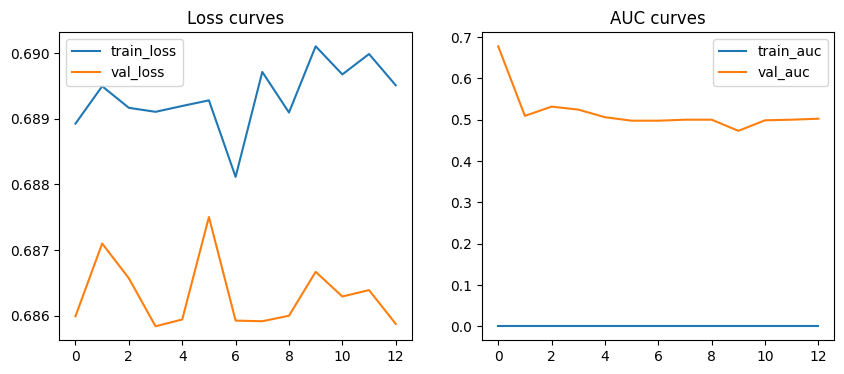

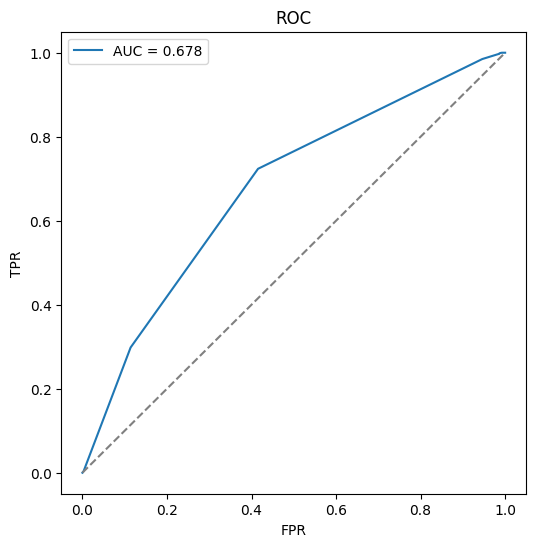

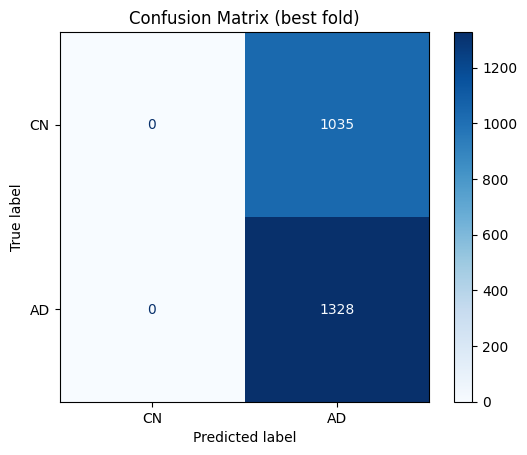

Classification report (best fold):
              precision    recall  f1-score   support

          CN       0.00      0.00      0.00      1035
          AD       0.56      1.00      0.72      1328

    accuracy                           0.56      2363
   macro avg       0.28      0.50      0.36      2363
weighted avg       0.32      0.56      0.40      2363



In [55]:

# Cell 16: Summarize CV results and plot training curves for best fold
# aggregate AUC and accuracy
aucs = [r['val_auc'] for r in results]
accs = [r['val_acc'] for r in results]
print('CV AUCs:', aucs)
print('Mean AUC:', np.mean(aucs), 'Std:', np.std(aucs))
print('Mean Acc:', np.mean(accs), 'Std:', np.std(accs))

# plot training curves for the best fold by AUC
best = max(results, key=lambda x: x['val_auc'])
history = best['history']
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history['train_loss'], label='train_loss')
plt.plot(history['val_loss'], label='val_loss')
plt.legend(); plt.title('Loss curves')
plt.subplot(1,2,2)
plt.plot(history['train_auc'], label='train_auc')
plt.plot(history['val_auc'], label='val_auc')
plt.legend(); plt.title('AUC curves')
plt.show()

# ROC and confusion matrix for best fold
from sklearn.metrics import roc_curve, auc, ConfusionMatrixDisplay
fpr, tpr, _ = roc_curve(best['val_trues'], best['val_preds'])
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC'); plt.legend(); plt.show()

cm = confusion_matrix(best['val_trues'], (best['val_preds']>=0.5).astype(int))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['CN','AD'])
disp.plot(cmap='Blues'); plt.title('Confusion Matrix (best fold)'); plt.show()

print('Classification report (best fold):')
print(classification_report(best['val_trues'], (best['val_preds']>=0.5).astype(int), target_names=['CN','AD']))


In [56]:

# Cell 17: Save consolidated best model (choosing best fold)
best_overall = max(results, key=lambda x: x['val_auc'])
final_best_path = '/mnt/data/final_best_model.pt'
# copy file
import shutil
shutil.copy(best_overall['ckpt'], final_best_path)
print('Saved final best model to', final_best_path)


Saved final best model to /mnt/data/final_best_model.pt


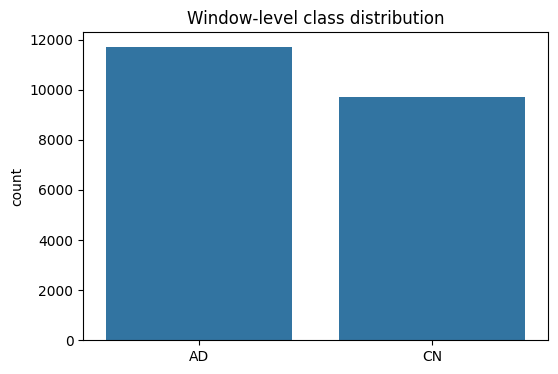

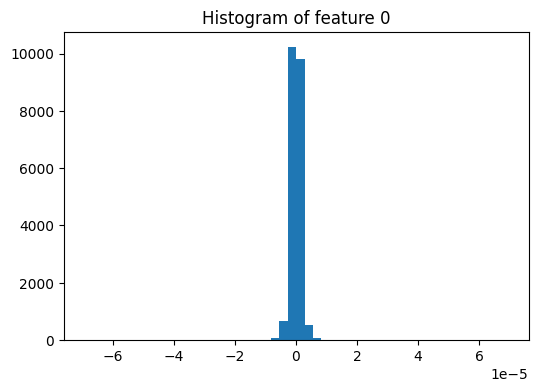

In [57]:

# Cell 18: Basic EDA - class distribution and feature histograms
plt.figure(figsize=(6,4))
sns.countplot(x=[ 'AD' if v==1 else 'CN' for v in y_all ])
plt.title('Window-level class distribution'); plt.show()

# Feature histogram for first feature dimension as example
plt.figure(figsize=(6,4))
plt.hist(X_all[:,0], bins=50); plt.title('Histogram of feature 0'); plt.show()


In [58]:

# Cell 19: t-SNE visualization (sample windows to keep it fast)
sample_n = min(2000, X_all.shape[0])
idx = np.random.choice(len(X_all), sample_n, replace=False)
X_emb = X_all[idx]
y_emb = y_all[idx]

tsne = TSNE(n_components=2, random_state=SEED, perplexity=30, n_iter=1000)
Z = tsne.fit_transform(X_emb)
plt.figure(figsize=(8,6))
plt.scatter(Z[:,0], Z[:,1], c=y_emb, cmap='coolwarm', s=10, alpha=0.7)
plt.title('t-SNE (sample windows)'); plt.show()


TypeError: TSNE.__init__() got an unexpected keyword argument 'n_iter'


## Notes & Next steps
- If `tqwt` is not installed, please run `pip install tqwt` in your environment and re-run the notebook (Cell 1). TQWT features are important for improved performance; the code will raise a clear error if TQWT isn't available when feature extraction runs.
- Feature extraction (Cell 9) can take significant time depending on your disk and CPU/GPU. Use the cache folder `/mnt/data/eeg_feature_cache` to avoid reprocessing.
- You can tune model hyperparameters in Cell 15 (batch size, learning rate, mixup alpha, model sizes).
- The notebook saves per-fold best checkpoints to `/mnt/data` and copies the best overall model to `/mnt/data/final_best_model.pt`.
